# Load the Dataset

In [57]:
import pandas as pd

data = pd.read_csv('D:\FYP\Code\Dataset\downsampled_data.csv')

In [58]:
X = data.drop(columns=['activity', 'id', 'time', 'rssi_1', 'rssi_2'])

Y  = data['activity']

In [60]:
X

,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,amplitude10_1,...,phase55_2,phase56_2,phase57_2,phase58_2,phase59_2,phase60_2,phase61_2,phase62_2,phase63_2,phase64_2
0,118.726577,5.0,29.732137,31.953091,33.241540,33.105891,32.249031,30.805844,29.068884,26.870058,...,-2.419938,-2.356194,-2.334921,-2.289626,-2.283154,-2.270689,-2.284887,-2.403778,-2.677945,3.141593
1,118.726577,5.0,28.600699,30.000000,31.064449,30.886890,29.546573,28.792360,26.925824,24.331050,...,3.082837,3.113029,3.141593,-3.110353,-3.072736,-3.061763,-3.091634,3.141593,2.782822,2.111216
2,118.726577,5.0,29.529646,30.886890,32.756679,33.015148,31.890437,31.112698,28.425341,25.806976,...,-1.267911,-1.249046,-1.212026,-1.161888,-1.152572,-1.124691,-1.172274,-1.292497,-1.681454,-2.466852
3,118.726577,5.0,29.000000,31.000000,32.062439,32.249031,31.780497,30.364453,28.231188,25.942244,...,-1.040581,-1.015303,-0.974597,-0.939717,-0.906750,-0.927295,-0.927295,-0.982794,-1.325818,-2.034444
4,118.726577,5.0,28.861739,30.805844,31.575307,32.249031,32.015621,30.066593,28.284271,25.709920,...,-3.020969,-2.991221,-2.961739,-2.919511,-2.896614,-2.896614,-2.896614,-2.999696,3.017238,2.356194
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116570,118.726577,5.0,7.280110,9.848858,11.661904,13.892444,16.124515,17.000000,17.464249,17.464249,...,-0.938047,-0.900275,-0.844154,-0.805803,-0.785398,-0.785398,-0.881872,-1.080839,-1.499489,-1.869295
116571,118.726577,5.0,13.000000,18.248288,24.083189,28.160256,31.256999,33.376639,33.734256,33.955854,...,0.743756,0.805803,0.868539,0.920926,0.934288,0.927295,0.888480,0.741947,0.394791,0.000000
116572,118.726577,5.0,13.038405,18.027756,24.041631,28.160256,31.320920,32.572995,34.176015,34.014703,...,-1.892547,-1.823351,-1.761981,-1.741532,-1.717875,-1.695151,-1.778293,-1.975688,-2.303611,-2.574863
116573,118.726577,5.0,11.180340,16.124515,22.022716,26.019224,29.017236,31.064449,32.249031,32.388269,...,-3.112189,-3.056087,-3.024484,-2.986596,-2.937575,-2.951604,-3.006065,3.141593,2.843094,2.466852


# Principle Component Analysis

In [61]:
from sklearn.decomposition import PCA

pca = PCA(n_components=1, svd_solver='full')

pca.fit(X)

PCA(n_components=1, svd_solver='full')

In [62]:
from joblib import dump

dump(pca, 'pca_model_n=1.joblib')

['pca_model_n=1.joblib']

In [63]:
X_pca = pd.DataFrame(pca.transform(X))

In [64]:
X_pca.shape

(116575, 1)

Explained variance ratio of the principal component(s)

In [65]:
explained_variance_ratio = pca.explained_variance_ratio_
print(explained_variance_ratio)

[0.43722543]


In [66]:
X_pca

,0
0,-33.968479
1,-34.854806
2,-35.048804
3,-33.586920
4,-34.826279
...,...
116570,-43.286276
116571,-43.412489
116572,-44.532264
116573,-47.292591


<Axes: >

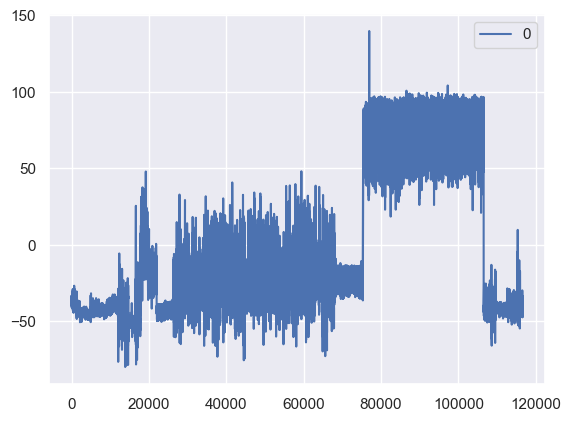

In [67]:
X_pca.plot()


Save PCA data to csv

In [68]:
X_pca.to_csv('pca_n=1.csv', index=False)

# Apply low pass filter

In [69]:
from scipy.signal import butter, filtfilt

# Filter parameters
cutoff_frequency = 10  # Cutoff frequency in Hz
sampling_frequency = 25  # Sampling frequency in Hz, adjust according to your data
filter_order = 5

def butter_lowpass_filter(data, cutoff, fs, order=5):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

Apply the low pass filter to the principal component

In [70]:
X_pca_filtered = butter_lowpass_filter(X_pca[0], cutoff_frequency, sampling_frequency, filter_order)

Save the PCA model

In [71]:
dump(pca, 'pca_model_n=1_filtered.joblib')

['pca_model_n=1_filtered.joblib']

Convert filtered principal component to DataFrame

<Axes: >

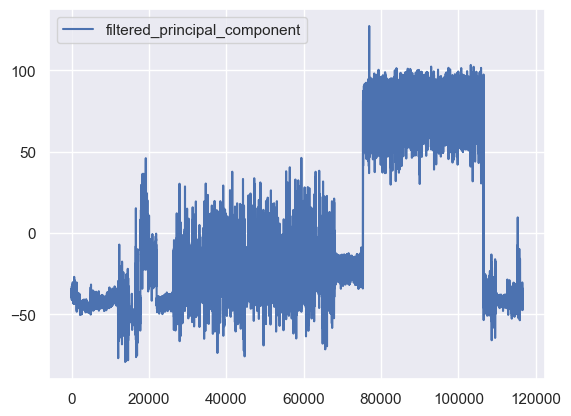

In [72]:
X_pca_filtered_df = pd.DataFrame(X_pca_filtered, columns=['filtered_principal_component'])

X_pca_filtered_df.plot()

### Filter with different parameters

(Parameters we used)

In [ ]:
# Define the filter parameters
order = 4
cutoff_freq = 0.005

# Create the filter coefficients
b, a = butter(order, cutoff_freq, btype='low', analog=False, output='ba')

filtered_data = X_pca.apply(lambda x: filtfilt(b, a, x))

In [ ]:
X_pca_filtered_df_new = pd.DataFrame(filtered_data, columns=[0])

X_pca_filtered_df_new.plot()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.lineplot(data=filtered_data[0])
plt.xlabel('Index')
plt.ylabel(f'PCA {1}')
plt.title(f'Plot of PCA {1}')
plt.show()


# Feature Extraction

Get dataframes count for each activity level from 0 to 5

In [73]:
for activity in range(6):
    activity_rows = X_pca_filtered_df[Y == activity]
    activity_rows_count = len(activity_rows)
    print(f'Activity {activity} rows count: {activity_rows_count}')

Activity 0 rows count: 45750
Activity 1 rows count: 16850
Activity 2 rows count: 14275
Activity 3 rows count: 10950
Activity 4 rows count: 15923
Activity 5 rows count: 12827


## Add Continuous Wavelet Transform and get Wavelet Variances

In [74]:
import pywt
import numpy as np

wavelet_name = 'db6' # Daubechies wavelet of order 6

In their study they have used Daubechies wavelet of order 6.
But, an error encountered is due to the ```db6``` wavelet not supporting the complex continuous wavelet transform (CWT).

In [75]:
scales = np.arange(1, 128)

wavelet_variances = np.empty((0, 26))

for activity in range(6):
    activity_rows = X_pca[Y == activity]
    activity_rows_count = len(activity_rows)
    for i in range(activity_rows_count // 25):
        csi = activity_rows.iloc[i*25:i*25+25, 0]
        coefficients, frequencies = pywt.cwt(csi, scales, 'gaus1')
        wavelet_variance = np.sum(coefficients**2, axis=0)
        wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, activity)))

In [81]:
wavelet_variances.shape

(4662, 26)

Export the calculated Wavelet variances.

In [82]:
wav = pd.DataFrame(wavelet_variances)
wav.to_csv('wavelet.csv', index=False)

In [2]:
import pandas as pd
import numpy as np

wav = pd.read_csv('wavelet.csv')
wav.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,839959.243090,762456.285367,672978.411250,579757.901931,485237.866754,391932.662056,303669.909289,222888.868566,154155.616232,94164.639235,...,92687.896739,152311.427636,221330.908754,302256.165800,389787.548214,484169.051659,578995.083881,673186.954847,762877.364930,0.0
1,846879.093278,770027.351857,680336.255078,585981.989244,490647.235760,396394.555084,307141.312241,225493.385574,155582.769150,95373.544505,...,92794.135539,152581.866777,221959.191126,303409.579372,391887.474158,487088.349918,583107.727881,677740.068440,768198.458216,0.0
2,879525.811182,800851.821319,708893.942137,612776.081891,515118.469058,418523.173957,326437.581216,241695.552874,168756.739675,105308.757090,...,89960.229648,150522.754478,221487.204575,305426.962855,397134.770041,496226.022422,596454.896333,696027.744590,791885.457841,0.0
3,871222.307518,787284.610062,690271.009545,589508.715795,488856.645821,390733.150568,298716.324672,215841.105503,146049.665719,86398.951496,...,107579.322665,171768.949232,244986.691951,330082.065422,421619.876002,519177.746241,616859.805253,712682.448727,803689.411432,0.0
4,858440.545170,778638.422910,685865.143572,589245.250504,491476.601711,395437.895577,304919.976012,222451.655124,152486.644742,92141.522423,...,98447.043051,159944.935615,230518.094363,313238.526581,402420.987924,498183.706622,594391.917004,689815.813845,781247.612349,0.0


# Classification

Get data into X and Y

In [3]:
X = wav.drop(columns=['25'])
Y = wav['25']

In [4]:
X.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,839959.243090,762456.285367,672978.411250,579757.901931,485237.866754,391932.662056,303669.909289,222888.868566,154155.616232,94164.639235,...,47818.453539,92687.896739,152311.427636,221330.908754,302256.165800,389787.548214,484169.051659,578995.083881,673186.954847,762877.364930
1,846879.093278,770027.351857,680336.255078,585981.989244,490647.235760,396394.555084,307141.312241,225493.385574,155582.769150,95373.544505,...,47723.733159,92794.135539,152581.866777,221959.191126,303409.579372,391887.474158,487088.349918,583107.727881,677740.068440,768198.458216
2,879525.811182,800851.821319,708893.942137,612776.081891,515118.469058,418523.173957,326437.581216,241695.552874,168756.739675,105308.757090,...,44823.485198,89960.229648,150522.754478,221487.204575,305426.962855,397134.770041,496226.022422,596454.896333,696027.744590,791885.457841
3,871222.307518,787284.610062,690271.009545,589508.715795,488856.645821,390733.150568,298716.324672,215841.105503,146049.665719,86398.951496,...,58256.370921,107579.322665,171768.949232,244986.691951,330082.065422,421619.876002,519177.746241,616859.805253,712682.448727,803689.411432
4,858440.545170,778638.422910,685865.143572,589245.250504,491476.601711,395437.895577,304919.976012,222451.655124,152486.644742,92141.522423,...,51795.850753,98447.043051,159944.935615,230518.094363,313238.526581,402420.987924,498183.706622,594391.917004,689815.813845,781247.612349


In [5]:
Y.head()
np.unique(Y)

array([0., 1., 2., 3., 4., 5.])

### [Optinal] Examine the recieved wavelet variences

Plot and view the behaviour of the wavelet column

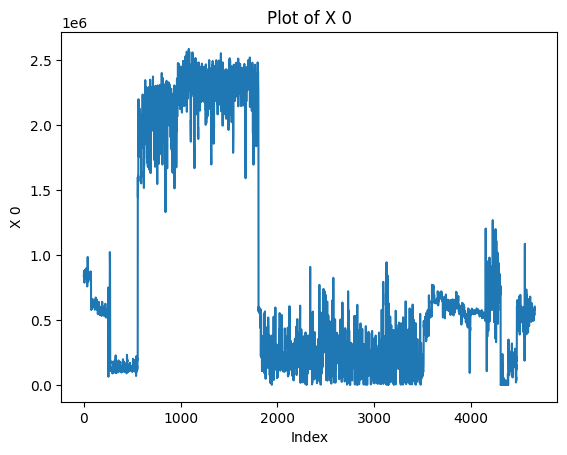

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select the desired column to plot
column = X.columns[0]

sns.lineplot(data=X[column])
plt.xlabel('Index')
plt.ylabel(f'X {column}')
plt.title(f'Plot of X {column}')
plt.show()

## Gausian Mixture Models

Create a list of Gaussian Mixture Models

In [7]:
from sklearn.mixture import GaussianMixture

n_classes = len(np.unique(Y))
gmm_models = [GaussianMixture(n_components=3, covariance_type='full') for _ in range(n_classes)]

Fit Gaussian Mixture Models for each class

In [8]:
for i in range(n_classes):
    class_data = X[Y == i]
    gmm_models[i].fit(class_data)

Get the predicted probabilities

In [9]:
predicted_probs = np.zeros((len(X), 6))

for i in range(6):
    # Calculate the log-likelihood scores for each sample in X using the Gaussian Mixture Model for the current class
    predicted_probs[:, i] = gmm_models[i].score_samples(X)


In [103]:
predicted_probs

array([[-164.61178369, -188.14379674, -215.54313826, -186.7607176 ,
        -172.74428973, -176.04379281],
       [-160.53996713, -182.30163098, -211.4180081 , -183.40494781,
        -164.82936803, -172.55049045],
       [-165.13433175, -185.58436716, -212.43845236, -185.03217013,
        -188.28406348, -174.27720795],
       ...,
       [-173.48895509, -188.82018657, -202.36677455, -188.26241441,
        -178.68410583, -182.13183585],
       [-236.89984099, -194.43132785, -205.43436486, -190.81502837,
        -202.17676503, -186.93200854],
       [-238.1631841 , -198.63820581, -206.59974444, -196.04960784,
        -235.96405138, -193.49521027]])

In [10]:
# Predict the labels by selecting the class with the highest probability for each sample
predicted_labels = np.argmax(predicted_probs, axis=1)

predicted_labels

array([0, 4, 0, ..., 0, 5, 5], dtype=int64)

## Results Evaluation

### Accuracy

In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y, predicted_labels)
print(f"Accuracy: {accuracy:.5f}")

Accuracy: 0.71858


### Confusion Matrix

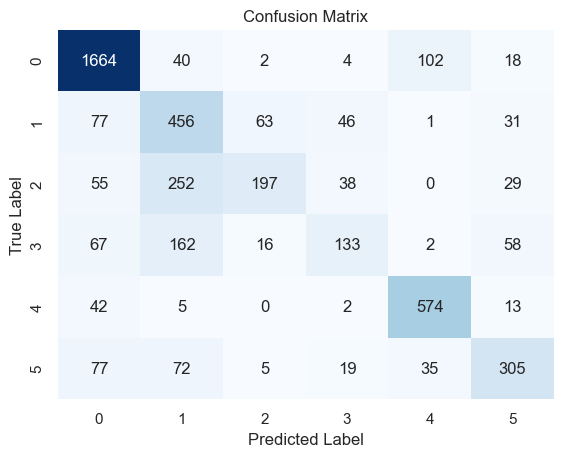

In [109]:
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(Y, predicted_labels)

# Plot the confusion matrix using seaborn heatmap
plt.figure()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

### Precision, Recall and F1 Score

F1 Score for all predictions

In [110]:
from sklearn.metrics import f1_score

f1 = f1_score(Y, predicted_labels, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.7008


Evaluation of each class separately

In [126]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(Y, predicted_labels, average=None)
recall = recall_score(Y, predicted_labels, average=None)
f1 = f1_score(Y, predicted_labels, average=None)

# Print results for each class
for class_label in range(6):
    print(f"Class {class_label}:", end="     ")
    print(f"Precision: {precision[class_label]:.4f}", end=",    ")
    print(f"Recall: {recall[class_label]:.4f}", end=",    ")
    print(f"F1 Score: {f1[class_label]:.4f}")

Class 0:     Precision: 0.8396,    Recall: 0.9093,    F1 Score: 0.8730
Class 1:     Precision: 0.4620,    Recall: 0.6766,    F1 Score: 0.5491
Class 2:     Precision: 0.6961,    Recall: 0.3450,    F1 Score: 0.4614
Class 3:     Precision: 0.5496,    Recall: 0.3037,    F1 Score: 0.3912
Class 4:     Precision: 0.8039,    Recall: 0.9025,    F1 Score: 0.8504
Class 5:     Precision: 0.6718,    Recall: 0.5945,    F1 Score: 0.6308


----


# Different Wavelet case

We need to use a wavelet that supports complex CWT. The ```'cmor'``` (complex Morlet wavelet) is a suitable alternative that supports complex CWT and is similar in nature to the Daubechies wavelets in terms of time-frequency localization.

In [ ]:
scales = np.arange(1, 128)

In [ ]:
wavelet_variances = np.empty((0, 26))

for activity in range(6):
    activity_rows = X_pca_filtered_df[Y == activity]
    activity_rows_count = len(activity_rows)
    for i in range(activity_rows_count // 25):
        csi = activity_rows.iloc[i*25:i*25+25, 0]
        coefficients, frequencies = pywt.cwt(csi, scales, 'cmor')
        wavelet_variance = np.sum(coefficients**2, axis=0)
        wavelet_variances = np.vstack((wavelet_variances, np.append(wavelet_variance, activity)))


In [ ]:
wavelet_variances.shape

In [ ]:
wav = pd.DataFrame(wavelet_variances)

wav.to_csv('wavelet_cmor1.5-1.0.csv', index=False)

In [ ]:
#optional
import pandas as pd

wav = pd.read_csv('wavelet_cmor1.5-1.0.csv')

In [ ]:
wav.head()

In [ ]:
X = wav.drop(columns=['25'])

Y = wav['25']

In [ ]:
X.head()

In [ ]:
Y.head()

In [ ]:
# Reset seaborn to its default parameters
sns.set()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# for column in X.columns:
#     sns.lineplot(data=X[column])
#     plt.xlabel('Index')
#     plt.ylabel(f'X {column}')
#     plt.title(f'Plot of X {column}')
#     plt.show()
column = X.columns[1]

sns.lineplot(data=X[column])
plt.xlabel('Index')
plt.ylabel(f'X {column}')
plt.title(f'Plot of X {column}')
plt.show()


```cmor``` Seems too complex as it results in a complex number output. 
I'm gonna go ahead with `gaus1` wavelet and check out, and if the time permits I'll come back and try out the predictions using cmor.